In [12]:
from pathlib import Path
BASE = Path("/home/lka/HYBRID_SARIMA")
print(BASE.exists(), BASE)

#Import the file to read it
import pandas as pd
disocupati_trimestral = pd.read_csv(BASE / 'data.csv', 
                       index_col='Period', 
                       parse_dates=True)
print(disocupati_trimestral)

True /home/lka/HYBRID_SARIMA
             15-34 M    15-34 F   35-49 M   35-49 F   50-74 M   50-74 F  \
Period                                                                    
2004-Q1    11.720628  17.198032  4.283283  8.776062  4.004764  5.376203   
2004-Q2    11.410664  16.187372  3.654493  7.196378  3.636536  4.515018   
2004-Q3    10.041510  15.682014  3.520125  6.945425  3.394804  3.976243   
2004-Q4    11.918557  17.227696  4.020448  7.582207  3.604743  3.583677   
2005-Q1    12.334781  16.852636  4.316241  7.577546  3.440298  4.204936   
...              ...        ...       ...       ...       ...       ...   
2025-Q2    11.341464  13.635416  5.106017  7.025122  3.776334  3.889283   
2025-Q3     9.628072  11.355385  4.656108  6.239399  3.108541  3.482718   
2025-Q4    10.903735  10.928362  3.989899  5.704370  3.250742  3.129547   
2026-Q1     9.534584  10.900056  4.316380  5.611548  2.984988  3.392216   
2026-Q2    10.244865  11.855438  5.044973  6.388627  3.268385  3.460483

In [13]:
#Dividir el dataset en training, validation y test
series = [
    '15-34 M', '15-34 F',
    '35-49 M', '35-49 F',
    '50-74 M', '50-74 F',
    'Global_Rate'
]

# Ordenar cronológicamente
df = disocupati_trimestral

# División 70% Train, 15% Validation, 15% Test
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = df[series].iloc[:train_end].copy()
val = df[series].iloc[train_end:val_end].copy()
test = df[series].iloc[val_end:].copy()

# Mostrar resultados para cada serie
#for serie in series:
#    print(f"\nSerie: {serie}")
#    print(f"Train: {len(train[serie])} observaciones")
#    print(f"Validation: {len(val[serie])} observaciones")
#    print(f"Test: {len(test[serie])} observaciones")

print(train)
print(val)
print(test)


             15-34 M    15-34 F   35-49 M    35-49 F   50-74 M   50-74 F  \
Period                                                                     
2004-Q1    11.720628  17.198032  4.283283   8.776062  4.004764  5.376203   
2004-Q2    11.410664  16.187372  3.654493   7.196378  3.636536  4.515018   
2004-Q3    10.041510  15.682014  3.520125   6.945425  3.394804  3.976243   
2004-Q4    11.918557  17.227696  4.020448   7.582207  3.604743  3.583677   
2005-Q1    12.334781  16.852636  4.316241   7.577546  3.440298  4.204936   
...              ...        ...       ...        ...       ...       ...   
2018-Q2    17.908050  21.321705  7.759217  10.435680  6.683032  6.283515   
2018-Q3    16.802144  19.343542  6.191831   9.120602  5.538136  5.299045   
2018-Q4    19.322895  22.132355  7.396393  10.673055  6.327076  6.189145   
2019-Q1    19.163606  21.713279  8.111591  11.250865  6.697788  6.034775   
2019-Q2    17.128382  19.347371  7.161324   9.818228  5.738406  5.356958   

           

In [14]:
import warnings
import optuna
import re
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from itertools import product
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)

SEED = 42
N_TRIALS = 2000  # Prueba inicial: 10 por serie; cambia a 500 para búsqueda completa
SEASON_LENGTH = 4
MAX_EPOCHS = 100
PATIENCE = 15

np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

ARCHITECTURES = [
    (32,), (64,), (128,), (32, 32), (64, 32), (64, 64),
    (128, 32), (128, 64), (128, 128)
]

OUTPUT = Path('results/SARIMA_LSTM_Optuna_Joint')
OUTPUT.mkdir(parents=True, exist_ok=True)


class LSTM(nn.Module):
    def __init__(self, neurons, dropout):
        super().__init__()
        self.layers = nn.ModuleList()
        size = 1
        for n in neurons:
            self.layers.append(nn.LSTM(size, n, batch_first=True))
            size = n
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(size, 1)

    def forward(self, x):
        for i, layer in enumerate(self.layers):
            x, _ = layer(x)
            if i == 0:
                x = self.drop(x)
        return self.fc(x[:, -1, :])


def sequences(z, w, start, end):
    if end <= start or start < w:
        raise ValueError('No hay suficientes datos para construir ventanas LSTM')
    X = np.array([z[i-w:i] for i in range(start, end)], dtype=np.float32)
    y = np.array(z[start:end], dtype=np.float32)
    return (torch.as_tensor(X.reshape(-1, w, 1), device=device),
            torch.as_tensor(y.reshape(-1, 1), device=device))


def train_lstm(res_train, res_val, sarima_val, y_val, config,
               final=False, best_epoch=None, trial=None):
    neurons, lr, w, epochs, batch, dropout = config
    torch.manual_seed(SEED)

    scaler = MinMaxScaler()
    a = scaler.fit_transform(np.asarray(res_train).reshape(-1, 1)).ravel()
    if len(a) <= w:
        raise ValueError('Muy pocos residuos para la ventana LSTM')

    if final:
        z = a
    else:
        b = scaler.transform(np.asarray(res_val).reshape(-1, 1)).ravel()
        z = np.concatenate([a, b])

    X, y = sequences(z, w, w, len(a))
    model = LSTM(neurons, dropout).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    best_mse, best_ep, wait = float('inf'), 0, 0

    if not final:
        Xv, _ = sequences(z, w, len(a), len(z))

    n_epochs = int(best_epoch) if final else epochs
    if n_epochs < 1:
        raise ValueError('El número de épocas debe ser positivo')

    for epoch in range(1, n_epochs + 1):
        model.train()
        idx = torch.randperm(len(X), device=device)
        for ids in idx.split(batch):
            optimizer.zero_grad()
            loss = criterion(model(X[ids]), y[ids])
            loss.backward()
            optimizer.step()

        if not final:
            model.eval()
            with torch.no_grad():
                pred = model(Xv).cpu().numpy()
            residual_pred = scaler.inverse_transform(pred).ravel()
            mse = mean_squared_error(y_val, sarima_val + residual_pred)
            if not np.isfinite(mse):
                raise ValueError('MSE no finito')

            if mse < best_mse - 1e-10:
                best_mse, best_ep, wait = mse, epoch, 0
            else:
                wait += 1

            if trial is not None:
                trial.report(float(best_mse), step=epoch)
                if trial.should_prune():
                    raise optuna.TrialPruned()

            if wait >= PATIENCE:
                break

    if final:
        model.eval()
        return model, scaler
    return float(best_mse), int(best_ep), int(epoch)


def search_one_series(y_train, y_val, series_name, study_name):
    """Cada trial elige SARIMA + LSTM, minimizando el MSE híbrido."""
    observed_val = y_val.to_numpy(dtype=float)
    sarima_cache = {}  # Evita recalcular un mismo SARIMA en varios trials.

    def objective(trial):
        order = tuple(trial.suggest_int(k, 0, 2) for k in ('p', 'd', 'q'))
        seasonal = tuple(trial.suggest_int(k, 0, 2) for k in ('P', 'D', 'Q')) + (SEASON_LENGTH,)
        arch_idx = trial.suggest_int('architecture_idx', 0, len(ARCHITECTURES)-1)
        lr = trial.suggest_categorical('lr', [0.01, 0.001])
        w = trial.suggest_categorical('window', [4, 6, 8])
        batch = trial.suggest_categorical('batch', [16, 32])
        dropout = trial.suggest_categorical('dropout', [0.1, 0.3, 0.5])
        config = (ARCHITECTURES[arch_idx], lr, w, MAX_EPOCHS, batch, dropout)

        key = (order, seasonal)
        if key not in sarima_cache:
            try:
                sarima = SARIMAX(
                    y_train, order=order, seasonal_order=seasonal,
                    enforce_stationarity=True, enforce_invertibility=True
                ).fit(disp=False, maxiter=200)
                if not sarima.mle_retvals.get('converged', False):
                    sarima_cache[key] = None
                else:
                    resid = np.asarray(sarima.resid, dtype=float)[sarima.loglikelihood_burn:]
                    sarima_val = np.asarray(sarima.forecast(steps=len(y_val)), dtype=float)
                    val_resid = observed_val - sarima_val
                    if (len(resid) <= max(8, w)
                        or not np.all(np.isfinite(resid))
                        or not np.all(np.isfinite(val_resid))):
                        sarima_cache[key] = None
                    else:
                        sarima_cache[key] = (resid, sarima_val, val_resid)
            except (ValueError, np.linalg.LinAlgError):
                sarima_cache[key] = None

        data = sarima_cache[key]
        if data is None:
            raise optuna.TrialPruned()
        resid, sarima_val, val_resid = data
        if len(resid) <= w:
            raise optuna.TrialPruned()

        try:
            mse, best_ep, trained = train_lstm(
                resid, val_resid, sarima_val, observed_val, config,
                trial=trial
            )
        except ValueError:
            raise optuna.TrialPruned()

        trial.set_user_attr('best_epoch', best_ep)
        trial.set_user_attr('epochs_trained', trained)
        trial.set_user_attr('neurons', str(config[0]))
        return mse

    study = optuna.create_study(
        study_name=study_name,
        storage=f'sqlite:///{(OUTPUT / "optuna_studies.db").as_posix()}',
        load_if_exists=True,
        direction='minimize',
        sampler=optuna.samplers.TPESampler(seed=SEED, multivariate=True),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=30, n_warmup_steps=20),
    )
    remaining = max(0, N_TRIALS - sum(
        t.state != optuna.trial.TrialState.WAITING for t in study.trials
    ))
    print(f'{series_name}: {len(study.trials)} pruebas guardadas, {remaining} pendientes; resultados en {OUTPUT}', flush=True)
    if remaining:
        study.optimize(objective, n_trials=remaining, show_progress_bar=True)
    complete = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    if not complete:
        raise RuntimeError(f'No hubo trials válidos para {series_name}')
    return study


def evaluate_test(y_train_val, y_test, order, seasonal, config, best_epoch):
    sarima = SARIMAX(
        y_train_val, order=order, seasonal_order=seasonal,
        enforce_stationarity=True, enforce_invertibility=True
    ).fit(disp=False, maxiter=200)

    residuals = np.asarray(sarima.resid, dtype=float)[sarima.loglikelihood_burn:]
    lstm, scaler = train_lstm(
        residuals, None, None, None, config,
        final=True, best_epoch=best_epoch
    )

    sarima_pred = np.asarray(sarima.forecast(steps=len(y_test)), dtype=float)
    history = list(residuals)
    lstm_pred = []
    w = config[2]

    for i in range(len(y_test)):
        x = scaler.transform(np.asarray(history[-w:]).reshape(-1, 1))
        x = torch.as_tensor(x.reshape(1, w, 1), dtype=torch.float32, device=device)
        with torch.no_grad():
            pred = lstm(x).cpu().numpy()
        predicted_resid = float(scaler.inverse_transform(pred)[0, 0])
        lstm_pred.append(predicted_resid)
        # Mismo protocolo del código original: tras el pronóstico del paso i,
        # se revela y_test[i] y puede usarse en el pronóstico siguiente.
        history.append(float(y_test.iloc[i]) - sarima_pred[i])

    lstm_pred = np.asarray(lstm_pred)
    hybrid_pred = sarima_pred + lstm_pred
    real = y_test.to_numpy(dtype=float)

    mae = mean_absolute_error(real, hybrid_pred)
    mse = mean_squared_error(real, hybrid_pred)
    rmse = np.sqrt(mse)
    mape = np.mean(np.abs((real - hybrid_pred) / real)) * 100 if np.all(real != 0) else np.nan
    values = y_train_val.to_numpy(dtype=float)
    scale = np.mean(np.abs(values[SEASON_LENGTH:] - values[:-SEASON_LENGTH]))
    mase = mae / scale if np.isfinite(scale) and scale > 0 else np.nan
    r2 = r2_score(real, hybrid_pred)

    pred_df = pd.DataFrame({
        'Observed': real, 'SARIMA': sarima_pred,
        'LSTM_Residual': lstm_pred, 'Hybrid': hybrid_pred
    }, index=y_test.index)

    return [mae, mse, rmse, mape, mase, r2], pred_df


def main(train, val, test):
    """Ejecuta 1 estudio Optuna independiente por columna de train/val/test."""

    results = []
    best_params = {}
    all_trials = []

    for col in train.columns:
        print(f'\n========== Optuna: serie {col} ==========', flush=True)
        y_train = train[col].astype(float).reset_index(drop=True)
        y_val = val[col].astype(float).reset_index(drop=True)
        y_test = test[col].astype(float)
        y_train_val = pd.concat([y_train, y_val], ignore_index=True)

        study = search_one_series(y_train, y_val, col, f'joint_{col}')
        best = study.best_trial
        params = best.params
        order = (params['p'], params['d'], params['q'])
        seasonal = (params['P'], params['D'], params['Q'], SEASON_LENGTH)
        config = (
            ARCHITECTURES[params['architecture_idx']], params['lr'],
            params['window'], MAX_EPOCHS, params['batch'], params['dropout']
        )
        best_epoch = int(best.user_attrs['best_epoch'])

        best_params[col] = {
            'SARIMA': (order, seasonal), 'LSTM': config,
            'Best_Epoch': best_epoch, 'MSE_Validation': best.value
        }
        metrics, preds = evaluate_test(
            y_train_val, y_test, order, seasonal, config, best_epoch
        )
        results.append([col] + metrics)
        safe_col = re.sub(r'[^\w.-]+', '_', str(col))
        preds.to_csv(OUTPUT / f'pred_{safe_col}.csv')

        trial_df = study.trials_dataframe(
            attrs=('number', 'value', 'params', 'user_attrs', 'state'),
            multi_index=False
        )
        trial_df.insert(0, 'Serie', col)
        all_trials.append(trial_df)
        print(f'{col}: Validation MSE={best.value:.4f}; Test MSE={metrics[1]:.4f}')

    grid_df = pd.concat(all_trials, ignore_index=True)
    completed = grid_df.loc[grid_df['state'].eq('COMPLETE')].copy()
    completed = completed.sort_values(['Serie', 'value']).reset_index(drop=True)
    completed['Rank'] = completed.groupby('Serie').cumcount() + 1
    completed.loc[completed['Rank'] <= 10].to_csv(
        OUTPUT / 'SARIMA_LSTM_Optuna_Top10.csv', index=False
    )
    grid_df.to_csv(OUTPUT / 'SARIMA_LSTM_Optuna_All_Trials.csv', index=False)

    results_df = pd.DataFrame(
        results, columns=['Serie', 'MAE', 'MSE', 'RMSE', 'MAPE', 'MASE', 'R2']
    )
    results_df.to_csv(OUTPUT / 'SARIMA_LSTM_Optuna_Test.csv', index=False)
    print(results_df.round(4))
    print(best_params)
    return results_df, best_params



In [ ]:
# INICIAR OPTUNA. Ejecuta esta celda después de cargar train, val y test.
# Primera ejecución: 10 trials por serie, para confirmar que todo funciona.
# Para la búsqueda larga cambia N_TRIALS = 500 en la celda anterior y vuelve a ejecutar.

print(f"GPU disponible: {torch.cuda.is_available()} | dispositivo: {device}", flush=True)
print(f"Series: {len(train.columns)} | Trials por serie: {N_TRIALS}", flush=True)
print(f"Los resultados se guardarán en: {OUTPUT}", flush=True)
results_df, best_params = main(train, val, test)
display(results_df)


GPU disponible: True | dispositivo: cuda
Series: 7 | Trials por serie: 2000
Los resultados se guardarán en: results/SARIMA_LSTM_Optuna_Joint

========== Optuna: serie 15-34 M ==========


[I 2026-11-10 11:21:50,512] A new study created in RDB with name: joint_15-34 M


15-34 M: 0 pruebas guardadas, 2000 pendientes; resultados en results/SARIMA_LSTM_Optuna_Joint


  0%|          | 0/2000 [00:00<?, ?it/s]

[I 2026-11-10 11:21:51,310] Trial 0 finished with value: 3.785040256743291 and parameters: {'p': 1, 'd': 2, 'q': 2, 'P': 1, 'D': 0, 'Q': 0, 'architecture_idx': 0, 'lr': 0.01, 'window': 8, 'batch': 16, 'dropout': 0.5}. Best is trial 0 with value: 3.785040256743291.
[I 2026-11-10 11:21:51,875] Trial 1 finished with value: 3.7434481649066766 and parameters: {'p': 1, 'd': 1, 'q': 0, 'P': 1, 'D': 0, 'Q': 0, 'architecture_idx': 3, 'lr': 0.001, 'window': 8, 'batch': 32, 'dropout': 0.5}. Best is trial 1 with value: 3.7434481649066766.
[I 2026-11-10 11:21:52,464] Trial 2 finished with value: 25.018328302204402 and parameters: {'p': 2, 'd': 2, 'q': 0, 'P': 0, 'D': 2, 'Q': 1, 'architecture_idx': 1, 'lr': 0.01, 'window': 4, 'batch': 32, 'dropout': 0.5}. Best is trial 1 with value: 3.7434481649066766.
[I 2026-11-10 11:21:53,096] Trial 3 finished with value: 80.46467277500108 and parameters: {'p': 2, 'd': 2, 'q': 2, 'P': 1, 'D': 2, 'Q': 0, 'architecture_idx': 1, 'lr': 0.001, 'window': 8, 'batch': 16

In [ ]:
# Academic style
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="paper", font_scale=1.3)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "mathtext.fontset": "cm",
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "pdf.fonttype": 42,
    "savefig.bbox": "tight"
})

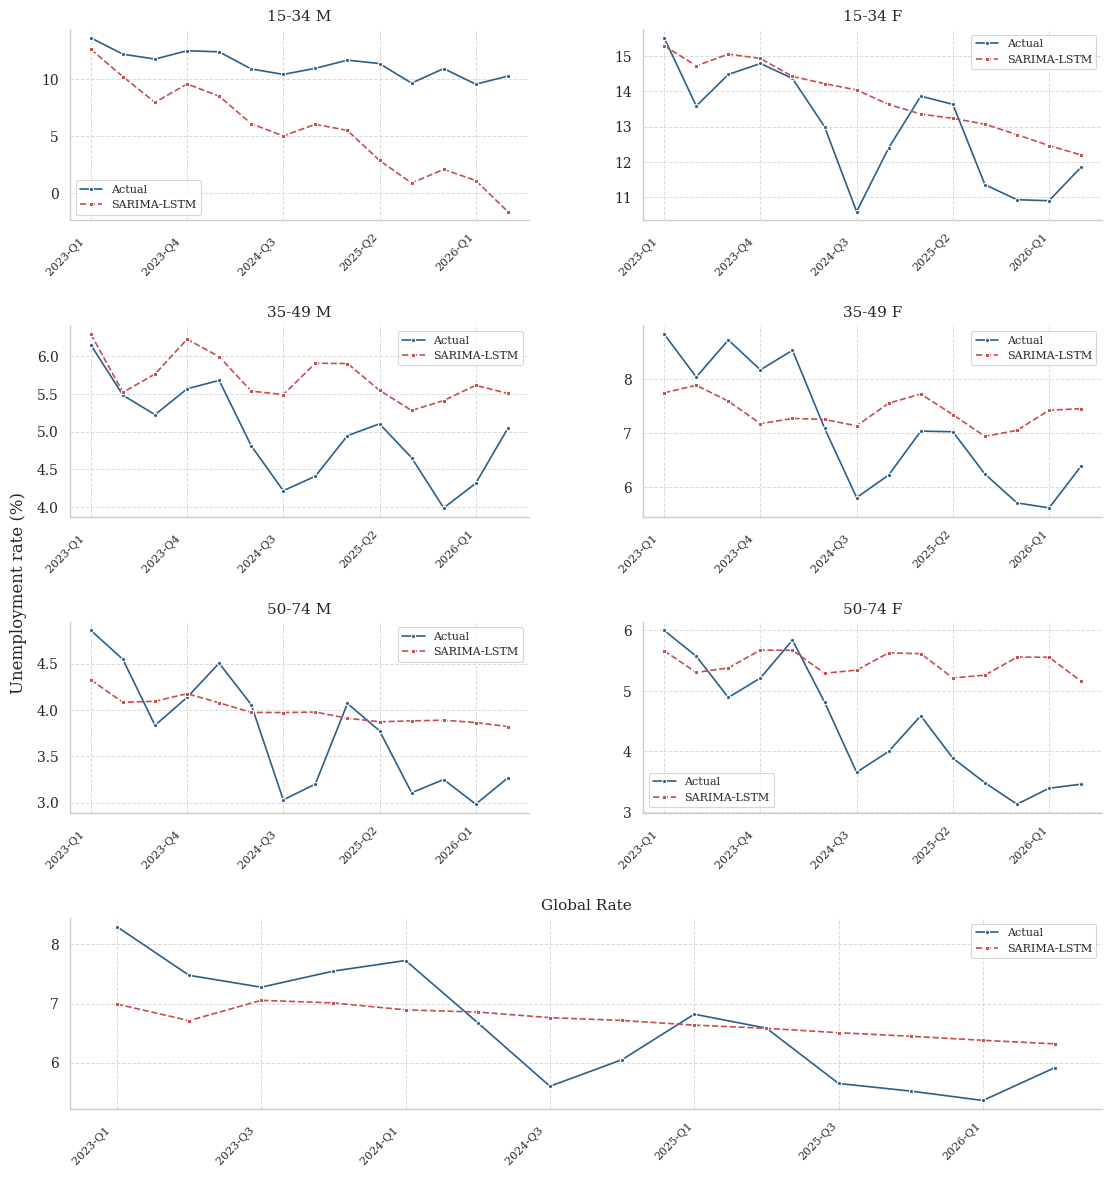

In [ ]:
series = ["15-34 M","15-34 F","35-49 M","35-49 F",
          "50-74 M","50-74 F","Global_Rate"]

fig = plt.figure(figsize=(12,12))
gs = fig.add_gridspec(4,2,hspace=0.55,wspace=0.25)
axes = [fig.add_subplot(gs[i//2,i%2]) for i in range(6)]
axes.append(fig.add_subplot(gs[3,:]))

for i,(ax,col) in enumerate(zip(axes,series)):
    #Leer predicciones del modelo Optuna conjunto
    #df = hybrid_predictions[col]
    df = pd.read_csv(BASE /"results"/"SARIMA_LSTM_Optuna_Joint" / f"pred_{col.replace(' ', '_')}.csv", index_col=0)
    x = df.index

    sns.lineplot(x=x,y=df["Observed"],ax=ax,color="#2B5F8A",
                 marker="o",markersize=3,linewidth=1.2,label="Actual")

    sns.lineplot(x=x,y=df["Hybrid"],ax=ax,color="#C44E52",
                 marker="s",markersize=3,linewidth=1.2,
                 linestyle="--",label="SARIMA-LSTM")

    ax.set_title(col.replace("_"," "),fontsize=11)
    ax.set(xlabel="",ylabel="")
    ticks = x[::2] if i==6 else x[::3]
    ax.set_xticks(ticks)
    ax.set_xticklabels(ticks,rotation=45,ha="right",fontsize=8)
    ax.grid(True,linestyle="--",linewidth=0.7,alpha=0.7)
    ax.legend(fontsize=8)
    sns.despine(ax=ax)

fig.supylabel("Unemployment rate (%)",fontsize=12,x=0.07)
fig.subplots_adjust(left=0.12,right=0.98,top=0.97,bottom=0.07)

IMG = BASE / "IMG"
IMG.mkdir(parents=True,exist_ok=True)
fig.savefig(IMG/"sarima_lstm_optuna_joint_forecast_test.pdf",bbox_inches="tight")
plt.show()